# Tugas Akhir 07 (TA-07): Implementasi dan Analisis Simulasi Sistem Dinamik
**Studi Kasus:** Simulasi Pertumbuhan Populasi Peternakan pada Kandang Terbatas

### 1. Formulasi Model Matematika
Model pertumbuhan populasi ternak dirumuskan menggunakan **Persamaan Diferensial Biasa (ODE) Model Logistik**:
$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right)$$

**Keterangan Variabel & Parameter:**
- $P$: Variabel Stock (Populasi Ternak dalam satuan ekor)
- $t$: Waktu simulasi (Bulan ke-0 s.d. Bulan ke-36)
- $P_0 = 250$: Populasi awal ternak (ekor)
- $r = 0.22$: Laju pertumbuhan intrinsik populasi ternak per bulan
- $K = 5000$: Kapasitas dukung maksimal kandang dan pakan (ekor)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Memuat Dataset Peternakan
df = pd.read_csv('data_populasi_peternakan.csv')
t_eval = df['Bulan'].values
P_asli = df['Populasi_Ternak'].values
P0 = P_asli[0]

print('5 Baris Pertama Dataset:')
display(df.head())

5 Baris Pertama Dataset:


,Bulan,Populasi_Ternak
0,0,250
1,1,296
2,2,433
3,3,592
4,4,543


### 2. Implementasi Kode Simulasi (Metode Euler & Validasi SciPy)

In [2]:
# Definisi fungsi ODE Model Logistik
def model_logistik_ternak(t, P, r, K):
    return r * P * (1 - P / K)

# Implementasi Metode Euler Manual
def simulasi_euler(func, P0, t_array, r, K):
    P = np.zeros(len(t_array))
    P[0] = P0
    for i in range(1, len(t_array)):
        dt = t_array[i] - t_array[i-1]  # step size h = 1 bulan
        P[i] = P[i-1] + dt * func(t_array[i-1], P[i-1], r, K)
    return P

# Parameter Baseline
r_base = 0.22
K_base = 5000

# Jalankan Simulasi Baseline
P_euler_base = simulasi_euler(model_logistik_ternak, P0, t_eval, r_base, K_base)
sol_scipy = solve_ivp(model_logistik_ternak, (t_eval[0], t_eval[-1]), [P0], args=(r_base, K_base), t_eval=t_eval)

### 3. Eksperimen Skenario (What-If Analysis)
- **Skenario 1 (Perluasan Kandang):** Kapasitas maksimal kandang ($K$) dinaikkan 40% dari $5.000$ menjadi $7.000$ ekor.
- **Skenario 2 (Penurunan Efisiensi Pakan / Wabah Ringan):** Laju pertumbuhan ($r$) turun 40% dari $0.22$ menjadi $0.132$ per bulan.

In [3]:
# Skenario 1: Perluasan Kandang (K = 7000)
K_scen1 = 7000
P_scen1 = simulasi_euler(model_logistik_ternak, P0, t_eval, r_base, K_scen1)

# Skenario 2: Penurunan Laju Pertumbuhan (r = 0.132)
r_scen2 = r_base * 0.6
P_scen2 = simulasi_euler(model_logistik_ternak, P0, t_eval, r_scen2, K_base)

# Simpan hasil simulasi ke dalam DataFrame
df_hasil = pd.DataFrame({
    'Bulan': t_eval,
    'Data_Asli_Ternak': P_asli,
    'Euler_Baseline': np.round(P_euler_base, 1),
    'SciPy_RK45': np.round(sol_scipy.y[0], 1),
    'Skenario_1_Perluasan_Kandang': np.round(P_scen1, 1),
    'Skenario_2_Penurunan_Laju_r': np.round(P_scen2, 1)
})
display(df_hasil.tail(10))

,Bulan,Data_Asli_Ternak,Euler_Baseline,SciPy_RK45,Skenario_1_Perluasan_Kandang,Skenario_2_Penurunan_Laju_r
27,27,4794,4763.7,4763.0,6504.6,3129.0
28,28,4756,4813.2,4808.2,6605.9,3283.6
29,29,4819,4852.8,4845.2,6687.7,3432.4
30,30,4823,4884.2,4875.2,6753.3,3574.4
31,31,5056,4909.1,4899.3,6805.7,3708.9
32,32,4917,4928.7,4918.6,6847.3,3835.4
33,33,4844,4944.2,4934.3,6880.1,3953.3
34,34,5017,4956.3,4947.2,6906.0,4062.5
35,35,4854,4965.9,4957.5,6926.4,4163.1
36,36,4983,4973.3,4965.8,6942.5,4255.1


### 4. Visualisasi & Analisis Perilaku Sistem

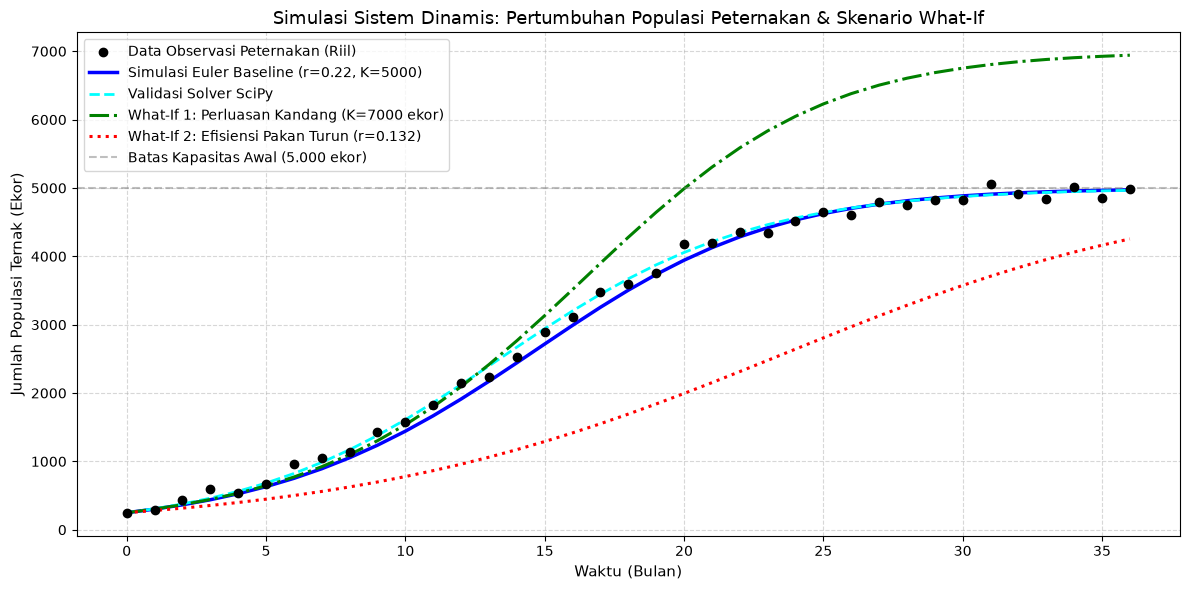

In [4]:
plt.figure(figsize=(12, 6))

# Plot Data Asli & Baseline
plt.scatter(t_eval, P_asli, color='black', label='Data Observasi Peternakan (Riil)', zorder=5)
plt.plot(t_eval, P_euler_base, color='blue', linewidth=2.5, label=f'Simulasi Euler Baseline (r={r_base}, K={K_base})')
plt.plot(t_eval, sol_scipy.y[0], color='cyan', linestyle='--', linewidth=2, label='Validasi Solver SciPy')

# Plot Skenario What-If
plt.plot(t_eval, P_scen1, color='green', linestyle='-.', linewidth=2.2, label=f'What-If 1: Perluasan Kandang (K={K_scen1} ekor)')
plt.plot(t_eval, P_scen2, color='red', linestyle=':', linewidth=2.2, label=f'What-If 2: Efisiensi Pakan Turun (r={r_scen2:.3f})')

plt.axhline(K_base, color='gray', linestyle='--', alpha=0.5, label='Batas Kapasitas Awal (5.000 ekor)')
plt.title('Simulasi Sistem Dinamis: Pertumbuhan Populasi Peternakan & Skenario What-If', fontsize=13)
plt.xlabel('Waktu (Bulan)', fontsize=11)
plt.ylabel('Jumlah Populasi Ternak (Ekor)', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5. Interpretasi Hasil Simulasi
1. **Kurva Sigmoid (S-Curve):** Pada kondisi baseline, populasi tumbuh cepat pada bulan ke-0 hingga ke-14 (*Reinforcing Loop* dominan), lalu melambat dan mencapai titik jenuh mendekati $K = 5.000$ ekor setelah bulan ke-24 (*Balancing Loop* menyeimbangkan sistem).
2. **Dampak Skenario 1 (Perluasan Kandang):** Menaikkan kapasitas $K$ menjadi $7.000$ ekor menggeser batas titik jenuh ke atas sehingga populasi mampu bertumbuh hingga $\pm 6.800$ ekor pada bulan ke-36.
3. **Dampak Skenario 2 (Penurunan Laju $r$):** Menurunkan laju pertumbuhan memperlambat waktu pencapaian kapasitas maksimal; hingga bulan ke-36 populasi baru mencapai $\pm 3.600$ ekor.